<a href="https://colab.research.google.com/github/raquetaaa/EZH2-ML-model-comparison/blob/main/EZH2_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install chembl_webresource_client
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 54.7 MB/s eta 0:00:00


In [2]:
import pandas as pd
from chembl_webresource_client.new_client import new_client
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import rdkit
from rdkit.Chem import rdFingerprintGenerator

/usr/local/lib/python3.13/dist-packages/chembl_webresource_client/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version


1. Getting the data

In [3]:
activities = new_client.activity.filter(target_chembl_id=['CHEMBL2189110'], pchembl_value__gte=5, assay_type='B').only(["molecule_chembl_id", "canonical_smiles", "standard_type",
"standard_relation", "standard_value","standard_units", "pchembl_value", "assay_chembl_id"])
activities_df=pd.DataFrame(activities)
activities_df.head()

,assay_chembl_id,canonical_smiles,molecule_chembl_id,pchembl_value,relation,standard_relation,standard_type,standard_units,standard_value,type,units,value
0,CHEMBL2209069,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,5.54,=,=,IC50,nM,2900.0,IC50,uM,2.9
1,CHEMBL2209069,Cc1cc(C)c(CNC(=O)c2cc(-c3ccc(N4CCN(C)CC4)nc3)c...,CHEMBL2204998,5.35,=,=,IC50,nM,4500.0,IC50,uM,4.5
2,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,6.76,=,=,IC50,nM,174.0,IC50,nM,174.0
3,CHEMBL2209076,Cc1cc(C)c(CNC(=O)c2cc(-c3ccnc(N4CCN(C)CC4)c3)c...,CHEMBL2204996,5.70,=,=,IC50,nM,1995.0,IC50,nM,1995.0
4,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccc(N3CCN(...,CHEMBL2204997,7.10,=,=,IC50,nM,79.0,IC50,nM,79.0


In [4]:
len(activities_df)

2142

2. Cleaning Data

In [5]:
activities_df=activities_df.query("standard_type == 'IC50' and standard_relation == '=' and standard_units=='nM'")
activities_df.drop(columns=["relation", "type", "units", "value"]) #assume ChEMBL standarization is correct
activities_df=activities_df.dropna(subset="canonical_smiles")


In [6]:
#convert to pIC50 for clarity
activities_df["pIC50"]= 9-np.log10((activities_df["standard_value"].astype(float)))
activities_df["pchembl_value"]= activities_df["pchembl_value"].astype(float)
activities_df.head()

,assay_chembl_id,canonical_smiles,molecule_chembl_id,pchembl_value,relation,standard_relation,standard_type,standard_units,standard_value,type,units,value,pIC50
0,CHEMBL2209069,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,5.54,=,=,IC50,nM,2900.0,IC50,uM,2.9,5.537602
1,CHEMBL2209069,Cc1cc(C)c(CNC(=O)c2cc(-c3ccc(N4CCN(C)CC4)nc3)c...,CHEMBL2204998,5.35,=,=,IC50,nM,4500.0,IC50,uM,4.5,5.346787
2,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,6.76,=,=,IC50,nM,174.0,IC50,nM,174.0,6.759451
3,CHEMBL2209076,Cc1cc(C)c(CNC(=O)c2cc(-c3ccnc(N4CCN(C)CC4)c3)c...,CHEMBL2204996,5.70,=,=,IC50,nM,1995.0,IC50,nM,1995.0,5.700057
4,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccc(N3CCN(...,CHEMBL2204997,7.10,=,=,IC50,nM,79.0,IC50,nM,79.0,7.102373


In [7]:
#group by structures (replicates) and set pIC50 as average
activities_df.groupby('molecule_chembl_id').agg({"pIC50":"mean", "canonical_smiles":"first"})


,pIC50,canonical_smiles
molecule_chembl_id,,
CHEMBL154745,7.096910,Nc1nccc2c1ncn2[C@@H]1C=C(CO)[C@@H](O)[C@H]1O
CHEMBL1570401,6.060481,O=C(O)C1Nc2ccc([N+](=O)[O-])cc2C2C=CCC12
CHEMBL1608462,5.468521,Cc1cc(C)c(CNC(=O)c2cc(C3CC3)nc3c2cnn3C(C)C)c(O)n1
CHEMBL2204995,6.994331,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...
CHEMBL2204996,5.700057,Cc1cc(C)c(CNC(=O)c2cc(-c3ccnc(N4CCN(C)CC4)c3)c...
...,...,...
CHEMBL6192512,8.468521,C=CC(=O)Nc1cc(CN2CCCCC2)ccc1-c1cc(C(=O)NCc2c(S...
CHEMBL6192723,8.481486,C/C=C/C(=O)Nc1cc(CN2CCOCC2)ccc1-c1cc(C(=O)NCc2...
CHEMBL6193304,8.602060,C=CC(=O)Nc1cc(CN2CCOCC2)ccc1-c1cc(C(=O)NCc2c(S...


In [8]:
activities_df["mol"]=activities_df.canonical_smiles.apply(rdkit.Chem.MolFromSmiles)
activities_df.head()

,assay_chembl_id,canonical_smiles,molecule_chembl_id,pchembl_value,relation,standard_relation,standard_type,standard_units,standard_value,type,units,value,pIC50,mol
0,CHEMBL2209069,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,5.54,=,=,IC50,nM,2900.0,IC50,uM,2.9,5.537602,<rdkit.Chem.rdchem.Mol object at 0x7ce20a929e70>
1,CHEMBL2209069,Cc1cc(C)c(CNC(=O)c2cc(-c3ccc(N4CCN(C)CC4)nc3)c...,CHEMBL2204998,5.35,=,=,IC50,nM,4500.0,IC50,uM,4.5,5.346787,<rdkit.Chem.rdchem.Mol object at 0x7ce20a929e00>
2,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,6.76,=,=,IC50,nM,174.0,IC50,nM,174.0,6.759451,<rdkit.Chem.rdchem.Mol object at 0x7ce20a92a030>
3,CHEMBL2209076,Cc1cc(C)c(CNC(=O)c2cc(-c3ccnc(N4CCN(C)CC4)c3)c...,CHEMBL2204996,5.70,=,=,IC50,nM,1995.0,IC50,nM,1995.0,5.700057,<rdkit.Chem.rdchem.Mol object at 0x7ce20a92a0a0>
4,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccc(N3CCN(...,CHEMBL2204997,7.10,=,=,IC50,nM,79.0,IC50,nM,79.0,7.102373,<rdkit.Chem.rdchem.Mol object at 0x7ce20a92a110>


3. Generate fingerprints

In [9]:
morgfpgen=rdFingerprintGenerator.GetMorganGenerator(radius=3,fpSize=2048)

In [10]:
activities_df["fp"]=activities_df.mol.apply(morgfpgen.GetFingerprint)
activities_df.head()

,assay_chembl_id,canonical_smiles,molecule_chembl_id,pchembl_value,relation,standard_relation,standard_type,standard_units,standard_value,type,units,value,pIC50,mol,fp
0,CHEMBL2209069,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,5.54,=,=,IC50,nM,2900.0,IC50,uM,2.9,5.537602,<rdkit.Chem.rdchem.Mol object at 0x7ce20a929e70>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."
1,CHEMBL2209069,Cc1cc(C)c(CNC(=O)c2cc(-c3ccc(N4CCN(C)CC4)nc3)c...,CHEMBL2204998,5.35,=,=,IC50,nM,4500.0,IC50,uM,4.5,5.346787,<rdkit.Chem.rdchem.Mol object at 0x7ce20a929e00>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."
2,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,6.76,=,=,IC50,nM,174.0,IC50,nM,174.0,6.759451,<rdkit.Chem.rdchem.Mol object at 0x7ce20a92a030>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."
3,CHEMBL2209076,Cc1cc(C)c(CNC(=O)c2cc(-c3ccnc(N4CCN(C)CC4)c3)c...,CHEMBL2204996,5.70,=,=,IC50,nM,1995.0,IC50,nM,1995.0,5.700057,<rdkit.Chem.rdchem.Mol object at 0x7ce20a92a0a0>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."
4,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccc(N3CCN(...,CHEMBL2204997,7.10,=,=,IC50,nM,79.0,IC50,nM,79.0,7.102373,<rdkit.Chem.rdchem.Mol object at 0x7ce20a92a110>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."


In [11]:
#convert to numpy arrays for regression models
from  rdkit import DataStructs
def fp_to_np(fp):
    arr = np.zeros((1,), dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr
activities_df["np_fp"]=activities_df.fp.apply(fp_to_np)
activities_df.dropna(subset="np_fp")
activities_df.head()


,assay_chembl_id,canonical_smiles,molecule_chembl_id,pchembl_value,relation,standard_relation,standard_type,standard_units,standard_value,type,units,value,pIC50,mol,fp,np_fp
0,CHEMBL2209069,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,5.54,=,=,IC50,nM,2900.0,IC50,uM,2.9,5.537602,<rdkit.Chem.rdchem.Mol object at 0x7ce20a929e70>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,CHEMBL2209069,Cc1cc(C)c(CNC(=O)c2cc(-c3ccc(N4CCN(C)CC4)nc3)c...,CHEMBL2204998,5.35,=,=,IC50,nM,4500.0,IC50,uM,4.5,5.346787,<rdkit.Chem.rdchem.Mol object at 0x7ce20a929e00>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccnc(N3CCN...,CHEMBL2204995,6.76,=,=,IC50,nM,174.0,IC50,nM,174.0,6.759451,<rdkit.Chem.rdchem.Mol object at 0x7ce20a92a030>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
3,CHEMBL2209076,Cc1cc(C)c(CNC(=O)c2cc(-c3ccnc(N4CCN(C)CC4)c3)c...,CHEMBL2204996,5.70,=,=,IC50,nM,1995.0,IC50,nM,1995.0,5.700057,<rdkit.Chem.rdchem.Mol object at 0x7ce20a92a0a0>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
4,CHEMBL2209076,CCCc1cc(C)[nH]c(=O)c1CNC(=O)c1cc(-c2ccc(N3CCN(...,CHEMBL2204997,7.10,=,=,IC50,nM,79.0,IC50,nM,79.0,7.102373,<rdkit.Chem.rdchem.Mol object at 0x7ce20a92a110>,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


5. Make models  (Random Forest and XGBoost)

In [12]:
import sklearn
from sklearn.model_selection import train_test_split
train_X, test_X, train_y, test_y = train_test_split(activities_df.np_fp, activities_df.pIC50, random_state=0)

In [13]:
from sklearn.ensemble import RandomForestRegressor
RFmodel=RandomForestRegressor(n_estimators=100, random_state=0)
RFmodel.fit(list(train_X), train_y)


RandomForestRegressor(random_state=0)

In [14]:
import xgboost as xgb
XGBmodel=xgb.XGBRegressor(n_estimators=100, random_state=0)
XGBmodel.fit(list(train_X), train_y)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

5. Evaluating the model

In [16]:
#Mean Absolute Error
from sklearn.metrics import mean_absolute_error
RFpIC50_pred=RFmodel.predict(list(test_X))
RFMAE=mean_absolute_error(test_y, RFpIC50_pred)
print(f"Mean Absolute Error for Random Forest Regressor: {RFMAE}")
#Errors good, but could bring down to 3 with parameter hypertuning

Mean Absolute Error for Random Forest Regressor: 0.4286412335185252


In [17]:
XGBpIC50_pred=XGBmodel.predict(list(test_X))
XGBMAE=mean_absolute_error(test_y, XGBpIC50_pred)
print(f"Mean Absolute Error for Extreme Gradient Boost Regressor: {XGBMAE}")
#Errors good, but could bring down to 3 with more parameters -> feature generator

Mean Absolute Error for Extreme Gradient Boost Regressor: 0.44894451326747337


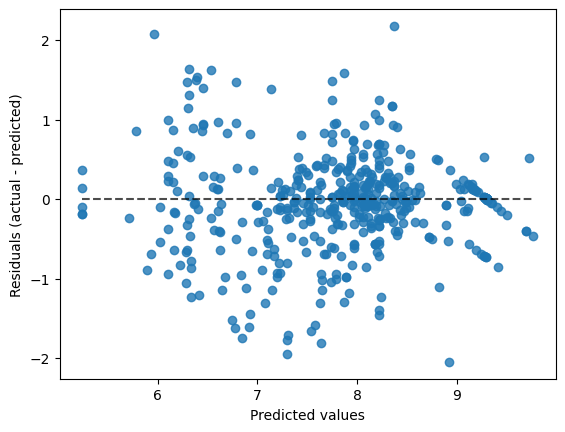

In [18]:
#Error
import matplotlib.pyplot as plt
from sklearn.metrics import PredictionErrorDisplay
display = PredictionErrorDisplay(y_true=test_y, y_pred=RFpIC50_pred)
display.plot()
plt.show()

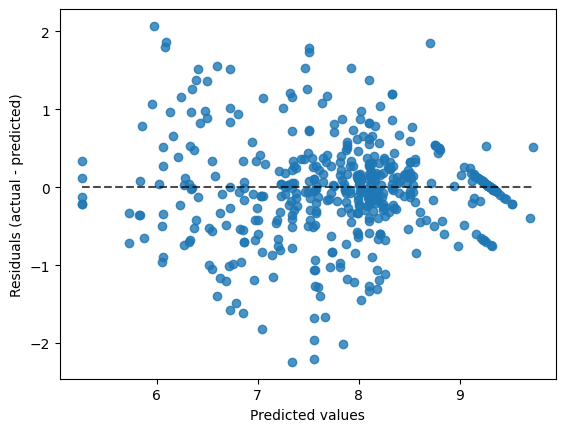

In [19]:
display = PredictionErrorDisplay(y_true=test_y, y_pred=XGBpIC50_pred)
display.plot()
plt.show()

In [22]:
#Verifying significance in error differences via Dietterich 5x2 cross folds validation.
import mlxtend
from mlxtend.evaluate import paired_ttest_5x2cv
t, p=paired_ttest_5x2cv(estimator1=RFmodel, estimator2=XGBmodel, X=list(train_X), y=train_y, random_seed=1)
print('t statistic: %.3f' % t)
print('p value: %.3f' % p)

t statistic: 1.637
p value: 0.163
